#Sql folder structure
Kenya_Mobile_Money_Project/
├── sql/
│   ├── 01_schema.sql
│   ├── 02_reference_data.sql
│   ├── 03_seed_data.sql
│   └── 04_queries.sql
├── docs/
├── README.md
└── .gitignore

#Python folder structure
Kenya_Mobile_Money_Project/
├── python/
│   ├── Data
│   ├── Notebooks
│   ├── venv
├── docs/
├── README.md
└── .gitignore


# KENYA MOBILE MONEY PROJECT: 
- Dataset: kenya_mobile_money_transactions.csv

- - 6,000 transactions across 800 customers, spanning 1 Jan 2024 → 31 Dec 2024.

The 10 Advanced Business Insights:

Solved in Python (pandas) and SQL.
Core skills : SQL, Python, 
- fluency in window functions, time-series grouping, and segmentation.

Note: analysis is only on >>  status = 'Completed' transactions unless stated otherwise

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')


In [2]:
mobile_money_data = pd.read_csv(r"J:\Porfolio_Projects\Kenya_Mobile_Money_Project\Python\Data\kenya_mobile_money_transactions.csv")

In [3]:
def quality_checks (df):
    print("="*45)
    print("Financial Data Overview:")
    print("="*45)
    df.info()
    print("="*45)
   
    print(f"First 10 rows:")
    print("="*45)
    print(display(df.head(10)))
    print("="*45)

    # Count exact Null values:
    print(f"Percentage of null values:\n {((df.isnull().sum())/(len(df))*100).round(2)}")
    print("="*45)

    # Count exact duplicate rows
    print(f"Number of Duplicates:\n{df.duplicated().sum()}")
    df.drop_duplicates()
    print("="*45)

quality_checks(mobile_money_data)


Financial Data Overview:
<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         6000 non-null   str    
 1   transaction_timestamp  6000 non-null   str    
 2   customer_id            6000 non-null   str    
 3   customer_name          6000 non-null   str    
 4   gender                 6000 non-null   str    
 5   age                    6000 non-null   int64  
 6   county                 6000 non-null   str    
 7   phone_number           6000 non-null   int64  
 8   channel                6000 non-null   str    
 9   transaction_type       6000 non-null   str    
 10  merchant_category      2449 non-null   str    
 11  device_type            6000 non-null   str    
 12  amount_kes             6000 non-null   float64
 13  transaction_fee_kes    6000 non-null   float64
 14  balance_after_kes      6000 non-null   flo

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status
0,TXN0000142,2024-01-01 07:51:33,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62.0,41335.52,Completed
1,TXN0002262,2024-01-01 07:54:30,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0.0,181880.31,Completed
2,TXN0004820,2024-01-01 08:07:24,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33.0,73354.11,Completed
3,TXN0003825,2024-01-01 08:35:18,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62.0,9511.86,Completed
4,TXN0003076,2024-01-01 09:02:16,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100.0,222644.38,Completed
5,TXN0001119,2024-01-01 10:13:41,CUST00080,Wairimu Karanja,Female,59,Nakuru,768299802,M-Pesa,Send Money,NaN,iOS,61662.04,108.0,148959.43,Completed
6,TXN0002858,2024-01-01 10:56:55,CUST00570,Maina Chepkwony,Male,59,Bungoma,790548571,M-Pesa,Pay Bill,Internet (ISP),Android,57898.44,108.0,29624.97,Completed
7,TXN0004575,2024-01-01 12:13:38,CUST00441,Otieno Otieno,Female,39,Nairobi,722426598,M-Pesa,Send Money,NaN,Feature Phone,34748.96,108.0,178642.16,Completed
8,TXN0004360,2024-01-01 13:05:27,CUST00759,Cheruiyot Kiplagat,Female,59,Nairobi,759119346,M-Pesa,Buy Goods (Till),Clothing,Android,18997.80,87.0,222838.81,Completed
9,TXN0003571,2024-01-01 13:11:25,CUST00765,Nyambura Mutiso,Male,61,Nairobi,710349640,Equitel,Pay Bill,Insurance,Feature Phone,16456.86,55.0,34488.35,Completed


None
Percentage of null values:
 transaction_id            0.00
transaction_timestamp     0.00
customer_id               0.00
customer_name             0.00
gender                    0.00
age                       0.00
county                    0.00
phone_number              0.00
channel                   0.00
transaction_type          0.00
merchant_category        59.18
device_type               0.00
amount_kes                0.00
transaction_fee_kes       0.00
balance_after_kes         0.00
status                    0.00
dtype: float64
Number of Duplicates:
0


In [4]:
merchant_categories = mobile_money_data['merchant_category'].dropna().unique().tolist()

print(sorted(merchant_categories))

['Clothing', 'DSTV/GOTV', 'Electricity (KPLC)', 'Electronics', 'Fuel Station', 'Hardware', 'Insurance', 'Internet (ISP)', 'Loan Repayment', 'Pharmacy', 'Rent', 'Restaurant', 'SACCO', 'School Fees', 'Supermarket', 'Water Utility']


## 1. Monthly revenue trend and month-over-month growth
Compute total fee revenue (transaction_fee_kes) per calendar month, then add a column showing the month-over-month % change. Which month grew fastest? 

(Skills: time bucketing, LAG() / .pct_change().)

In [5]:

#Set a datetime Index on the timestamp column.

mobile_money_data['transaction_timestamp']= pd.to_datetime(mobile_money_data['transaction_timestamp'])
mobile_money_data.set_index(['transaction_timestamp'], inplace=True, drop=False)

#Use resample() to bucket monthly revenue per month
monthly_rev_trend = mobile_money_data['transaction_fee_kes'].resample('MS').sum().rename("Monthly Revenue trend")

print(monthly_rev_trend)


transaction_timestamp
2024-01-01    33876.0
2024-02-01    31452.0
2024-03-01    33417.0
2024-04-01    33705.0
2024-05-01    37474.0
2024-06-01    31925.0
2024-07-01    33923.0
2024-08-01    32716.0
2024-09-01    32513.0
2024-10-01    34355.0
2024-11-01    33452.0
2024-12-01    33501.0
Freq: MS, Name: Monthly Revenue trend, dtype: float64


<Axes: title={'center': 'Revenue tren per month'}, xlabel='transaction_timestamp'>

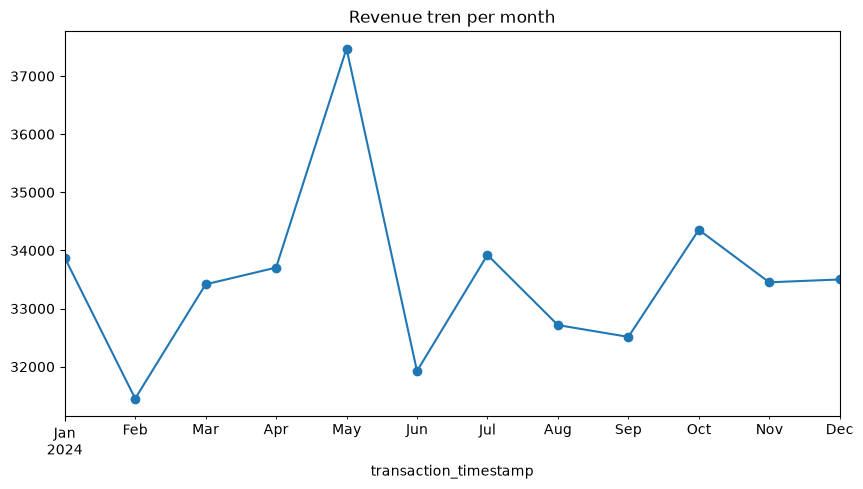

In [6]:
# Visualisation:

plt.figure(figsize=(10,5))
monthly_rev_trend.plot(kind='line', marker='o',title='Revenue tren per month')

In [7]:
# Add a column showing the month-over-month % change. Which month grew fastest? 

# Reset the index and convert monthly rev trend to a dataframe and rename the columns
monthly_change = monthly_rev_trend.reset_index()
monthly_change.columns = ['Month','Revenue']

monthly_change['Percentage_change']= monthly_change['Revenue'].pct_change() * 100



display(round(monthly_change,4))

#  Finding the month with the highest increase in Revenue

fastest_growth = monthly_change.loc[monthly_change['Percentage_change'].idxmax()]

print(f"Fastest growing month :\n {fastest_growth}")


,Month,Revenue,Percentage_change
0,2024-01-01,33876.0,NaN
1,2024-02-01,31452.0,-7.1555
2,2024-03-01,33417.0,6.2476
3,2024-04-01,33705.0,0.8618
4,2024-05-01,37474.0,11.1823
5,2024-06-01,31925.0,-14.8076
6,2024-07-01,33923.0,6.2584
7,2024-08-01,32716.0,-3.5581
8,2024-09-01,32513.0,-0.6205
9,2024-10-01,34355.0,5.6654


Fastest growing month :
 Month                2024-05-01 00:00:00
Revenue                          37474.0
Percentage_change              11.182317
Name: 4, dtype: object


## 2. Peak transaction hours (heatmap-ready)
Build a day-of-week × hour-of-day matrix of transaction counts. Identify the single busiest hour block. 

(Skills: extracting hour & weekday from a timestamp, pivoting.)

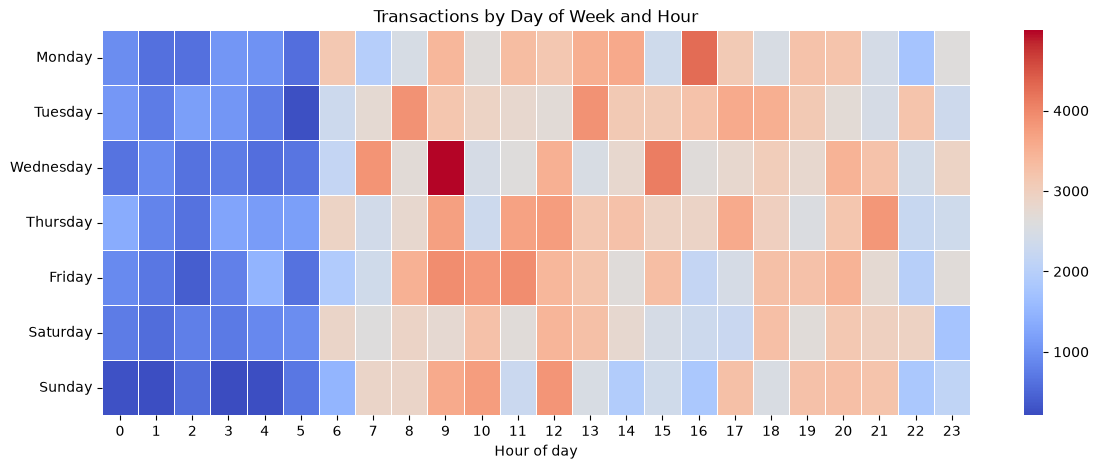

In [8]:

#Set a datetime Index on the timestamp column.

mobile_money_data['transaction_timestamp']= pd.to_datetime(mobile_money_data['transaction_timestamp'])
mobile_money_data.set_index(['transaction_timestamp'], inplace=True, drop=False)


# Extract Hour and Weekday from the timestamp

mobile_money_data['Hourly'] = mobile_money_data['transaction_timestamp'].dt.hour
mobile_money_data['Day'] = mobile_money_data['transaction_timestamp'].dt.day_name()

# Create a heatmap.pivot_table( rows = weekday, columns = hours, values = transaction_fees )

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday','Friday', 'Saturday', 'Sunday']
heatmap_data = mobile_money_data.pivot_table(
    index='Day', columns='Hourly',
    values='transaction_fee_kes', aggfunc='sum', fill_value=0
).reindex(index=day_order, columns=range(24), fill_value=0)

plt.figure(figsize=(14, 5))
sns.heatmap(heatmap_data, cmap='coolwarm', linewidths=0.5)
plt.title('Transactions by Day of Week and Hour')
plt.xlabel('Hour of day')
plt.ylabel('')
plt.show()



In [9]:
# Identify the single busiest hour block. 

stacked = heatmap_data.stack()           
busiest_day, busiest_hour = stacked.idxmax()

print(f"Busiest block: \n{busiest_day}, {busiest_hour:02d}:00-{busiest_hour:02d}:59")

Busiest block: 
Wednesday, 09:00-09:59


## 3. Top customers by value, ranked within their county
For each county, rank customers by total amount transacted and return the top 3 per county. 

-(Skills: RANK() / ROW_NUMBER() partitioned by county, or groupby().rank().)

In [10]:
mobile_money_data.columns

Index(['transaction_id', 'transaction_timestamp', 'customer_id',
       'customer_name', 'gender', 'age', 'county', 'phone_number', 'channel',
       'transaction_type', 'merchant_category', 'device_type', 'amount_kes',
       'transaction_fee_kes', 'balance_after_kes', 'status', 'Hourly', 'Day'],
      dtype='str')

In [11]:
counties = mobile_money_data['county'].unique()

In [12]:
#calculate total spend per customer and group by county.
customer_spend = mobile_money_data.groupby(
                                            ['customer_id','customer_name','county'],as_index=False).agg(total_spend=('amount_kes','sum'))
print("Top Spender:")
print("=="*45)
display(customer_spend.head(5))
print("--"*45)


# Group by county and rank according to spending
customer_spend['customer_rank'] = (customer_spend.groupby('county',)['total_spend'].rank(method='first', ascending=False))


# #@Filter out the  top 3
# top_3 = customer_spend[customer_spend['customer_rank'] <=3].sort_values(['customer_rank','county'],ascending=True).reset_index(drop=True)
# print("--"*45)
# display(top_3)



top3 = (
    customer_spend.groupby("county", group_keys=False)
      .apply(lambda x: x.nlargest(3, "total_spend"))
      .reset_index(drop=True)
      
)

display(top3)            



Top Spender:


,customer_id,customer_name,county,total_spend
0,CUST00001,Otieno Makau,Nairobi,104013.95
1,CUST00002,Kiptoo Njoroge,Kakamega,437940.87
2,CUST00003,Maina Mutiso,Nairobi,250682.84
3,CUST00004,Rotich Wanjala,Uasin Gishu,203768.05
4,CUST00005,Nyambura Ruto,Nairobi,183894.74


------------------------------------------------------------------------------------------


,customer_id,customer_name,total_spend,customer_rank
0,CUST00465,Mutua Musyoka,330868.23,1.0
1,CUST00018,Njoroge Waweru,316139.65,2.0
2,CUST00709,Kagwe Kamau,310710.67,3.0
3,CUST00229,Rotich Gichuru,482960.60,1.0
4,CUST00742,Anyango Ochieng,435283.01,2.0
5,CUST00331,Nafula Langat,417257.26,3.0
6,CUST00573,Kagwe Chepkwony,389269.04,1.0
7,CUST00320,Ochieng Waweru,306343.71,2.0
8,CUST00388,Njoroge Kiplagat,282178.41,3.0
9,CUST00685,Njoroge Musyoka,471429.90,1.0


In [ ]:
num_transactions = mobile_money_data[mobile_money_data['customer_name']=='Otieno Makau']

print(f"Total number of transactions by Otieno:\n", num_transactions['amount_kes'].sum())



Total number of transactions by Otieno:
 104013.95


## 4. 7-day rolling transaction volume
Create a daily transaction-count series, then compute the 7-day rolling average of daily volume. On how many days did volume exceed 1.5× its rolling average? 

(Skills: resampling to daily, rolling windows.)


In [25]:
# Convert the timestamp column into date_time index

mobile_money_data['transaction_timestamp']= pd.to_datetime(mobile_money_data['transaction_timestamp'])
mobile_money_data.set_index(['transaction_timestamp'], inplace=True, drop=False)

#Use resample() to bucket transactions into daily count series
daily = mobile_money_data['transaction_id'].resample('D').count().to_frame(name='daily volume')

# Compute the 7 day rolling volume

daily['rolling_avg'] = daily["daily volume"].rolling(window=7).mean()

# How many days did the volume exceed 1.5* rolling average
exceeding_days = daily[daily["daily volume"] > 1.5 * daily["rolling_avg"]]

print(f"Total Number of days:\n", len(exceeding_days))



Total Number of days:
 4


In [ ]:
mobile_money_data

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status,Hourly,Day
transaction_timestamp,,,,,,,,,,,,,,,,,,
2024-01-01 07:51:33,TXN0000142,2024-01-01 07:51:33,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62.0,41335.52,Completed,7,Monday
2024-01-01 07:54:30,TXN0002262,2024-01-01 07:54:30,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0.0,181880.31,Completed,7,Monday
2024-01-01 08:07:24,TXN0004820,2024-01-01 08:07:24,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33.0,73354.11,Completed,8,Monday
2024-01-01 08:35:18,TXN0003825,2024-01-01 08:35:18,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62.0,9511.86,Completed,8,Monday
2024-01-01 09:02:16,TXN0003076,2024-01-01 09:02:16,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100.0,222644.38,Completed,9,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 16:43:40,TXN0002555,2024-12-31 16:43:40,CUST00669,Kirui Njuguna,Male,65,Kiambu,111726719,Airtel Money,Airtime Purchase,NaN,Android,447.37,0.0,48148.09,Completed,16,Tuesday
2024-12-31 17:15:38,TXN0002692,2024-12-31 17:15:38,CUST00395,Nyambura Odhiambo,Male,36,Machakos,759145902,M-Pesa,Send Money,NaN,Android,11135.76,62.0,87648.22,Completed,17,Tuesday
2024-12-31 17:52:33,TXN0003223,2024-12-31 17:52:33,CUST00036,Akinyi Amollo,Female,64,Turkana,768858742,M-Pesa,Airtime Purchase,NaN,Android,730.68,0.0,118570.69,Completed,17,Tuesday


The 10 Advanced Questions
Solve each question twice — once in Python (pandas) and once in SQL. Compare your answers. The point is to build fluency in window functions, time-series grouping, and segmentation, not just simple aggregation.

Note: analyse only status = 'Completed' transactions unless a question says otherwise.

1. Monthly revenue trend and month-over-month growth
Compute total fee revenue (transaction_fee_kes) per calendar month, then add a column showing the month-over-month % change. Which month grew fastest? (Skills: time bucketing, LAG() / .pct_change().)

2. Peak transaction hours (heatmap-ready)
Build a day-of-week × hour-of-day matrix of transaction counts. Identify the single busiest hour block. (Skills: extracting hour & weekday from a timestamp, pivoting.)

3. Top customers by value, ranked within their county
For each county, rank customers by total amount transacted and return the top 3 per county. (Skills: RANK() / ROW_NUMBER() partitioned by county, or groupby().rank().)

4. 7-day rolling transaction volume
Create a daily transaction-count series, then compute the 7-day rolling average of daily volume. On how many days did volume exceed 1.5× its rolling average? (Skills: resampling to daily, rolling windows.)

5. Customer RFM segmentation
For every customer compute Recency (days since last transaction, relative to the dataset's max date), Frequency (number of transactions), and Monetary (total amount). Score each into quintiles (1–5) and label the top segment as "Champions". (Skills: multi-metric aggregation, quantile bucketing, NTILE().)

6. Failure/reversal rate by channel and transaction type
Using all statuses, compute the percentage of transactions that are Failed or Reversed, broken down by channel × transaction_type. Which combination is least reliable? (Skills: conditional aggregation, ratio over groups.)

7. Fee efficiency by transaction band
Bucket transactions into amount bands (0–500, 501–1,000, 1,001–5,000, 5,001–20,000, 20,000+) and compute the average effective fee rate (fee / amount) per band. Does the fee structure favour large or small transactions? (Skills: CASE / pd.cut, ratio metrics.)

8. Customer inter-transaction gap
For each customer, order their transactions by time and compute the average number of days between consecutive transactions. List the 10 most active (smallest average gap) customers. (Skills: LAG() over a partition ordered by time, or groupby().diff().)

9. Monthly new vs returning customers (cohorts)
Assign each customer to the month of their first transaction (their cohort). For each subsequent month, count how many customers are transacting for the first time ("new") vs already seen ("returning"). (Skills: first-seen per group, cohort assignment, self-comparison across periods.)

10. County revenue concentration (Pareto / 80-20)
Rank counties by total transaction value and compute the cumulative % of total value. How few counties account for 80% of all money moved? (Skills: ordered cumulative sums, window SUM() OVER (ORDER BY ...), Pareto analysis.)



Start from the questions the database must answer, not from tables. For example:

What is the daily transaction volume and value?
Which counties and agents handle the most cash-in and cash-out?
How much fee revenue do we earn per month?
Which customers are dormant (no activity in 30 days)?
What is the failed-transaction rate by type?

Suggested Deliverables
A Jupyter notebook (.ipynb) with a pandas solution for each question.
A .sql file with one query per question.
A short write-up (3–5 bullet points) of the business insights you found — e.g. which counties to prioritise, which channel is least reliable, when the platform is busiest.
Bonus: turn Questions 1, 2, and 10 into charts (Matplotlib/Seaborn or Power BI).
